In [2]:
# Analise dos experimentos

from pathlib import Path
import json
import math
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

from run_experiments import _build_experiments, _config_for_experiment
from src.features import load_feature_loaders
from src.model import build_feature_classifier
from src.utils import load_config, set_seed

CONFIG_PATH = Path("config.yaml")
config = load_config(CONFIG_PATH)
set_seed(config.get("seed", 42))

OUTPUT_ROOT = Path(config["training"]["output_dir"]) / "teste2"
ANALYSIS_DIR = Path(config["training"]["output_dir"]) / "analysis_teste2"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_NAME = config["training"].get("checkpoint_name", "best_model.pt")
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

print(f"Resultados esperados em: {OUTPUT_ROOT}")
print(f"Saidas da analise em: {ANALYSIS_DIR}")
## Carregamento dos resultados
def load_metrics(path):
    path = Path(path)
    if not path.exists():
        return None
    with open(path, "r", encoding="utf-8") as file:
        return json.load(file)



Resultados esperados em: outputs/teste2
Saidas da analise em: outputs/analysis_teste2


In [3]:
experiments = _build_experiments(config)
records = []

for experiment in experiments:
    exp_config = _config_for_experiment(config, experiment, OUTPUT_ROOT)
    output_dir = Path(exp_config["training"]["output_dir"])
    metrics = load_metrics(output_dir / "metrics.json")
    checkpoint_path = output_dir / CHECKPOINT_NAME
    records.append(
        {
            "experiment": experiment,
            "config": exp_config,
            "output_dir": output_dir,
            "metrics": metrics,
            "checkpoint_path": checkpoint_path,
        }
    )

finished = [record for record in records if record["metrics"] is not None]
print(f"Experimentos configurados: {len(records)}")
print(f"Experimentos com metrics.json: {len(finished)}")
for record in records:
    status = "ok" if record["metrics"] is not None else "sem metrics.json"
    ckpt = "com checkpoint" if record["checkpoint_path"].exists() else "sem checkpoint"
    print(f"{record['experiment']['name']}: {status}, {ckpt}")



Experimentos configurados: 13
Experimentos com metrics.json: 13
mlp_raw: ok, com checkpoint
mlp_pca_angle_4q: ok, com checkpoint
quantum_angle_4q: ok, com checkpoint
mlp_pca_angle_6q: ok, com checkpoint
quantum_angle_6q: ok, com checkpoint
mlp_pca_angle_8q: ok, com checkpoint
quantum_angle_8q: ok, com checkpoint
mlp_pca_amplitude_4q: ok, com checkpoint
quantum_amplitude_4q: ok, com checkpoint
mlp_pca_amplitude_6q: ok, com checkpoint
quantum_amplitude_6q: ok, com checkpoint
mlp_pca_amplitude_8q: ok, com checkpoint
quantum_amplitude_8q: ok, com checkpoint


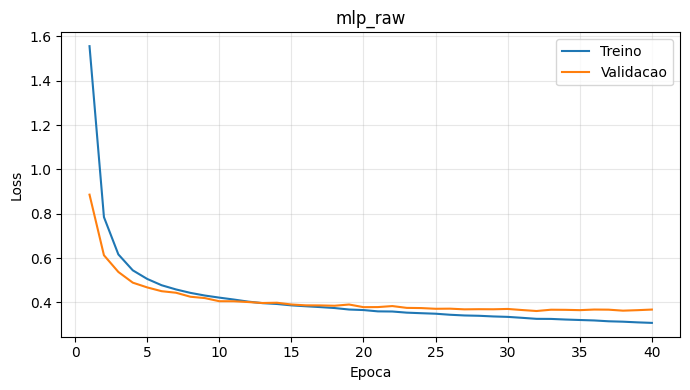

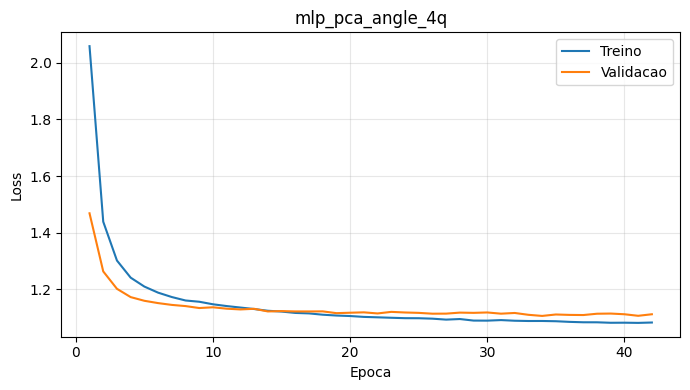

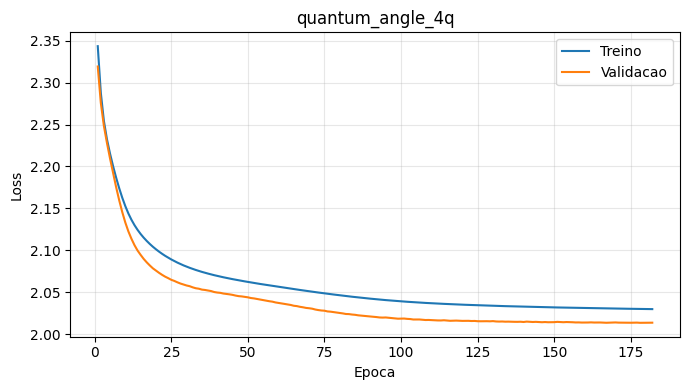

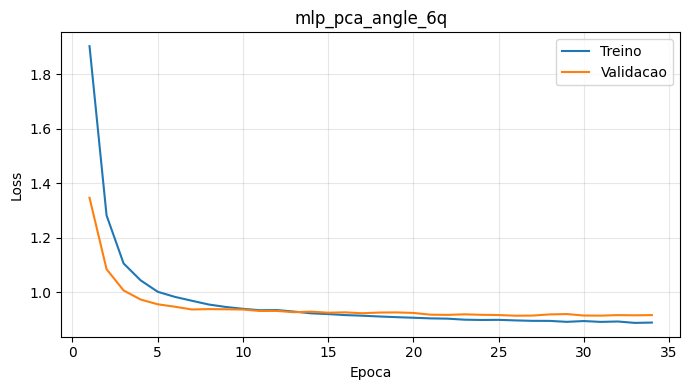

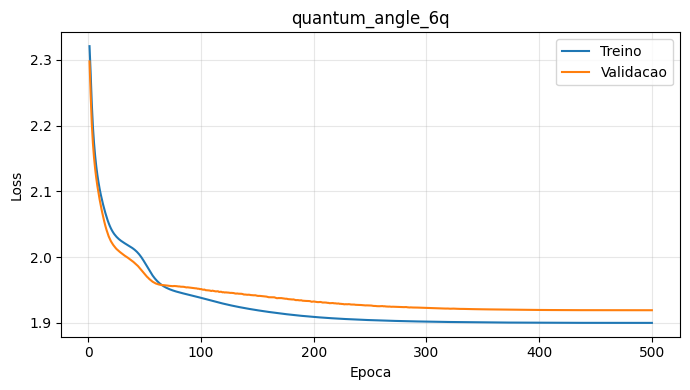

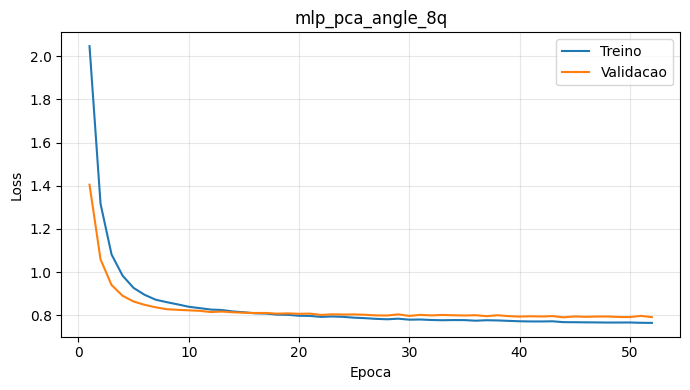

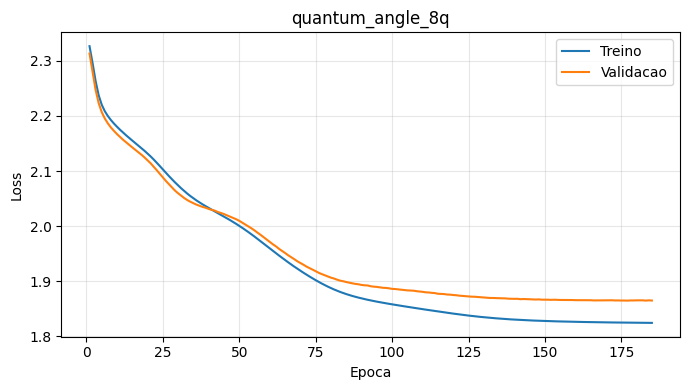

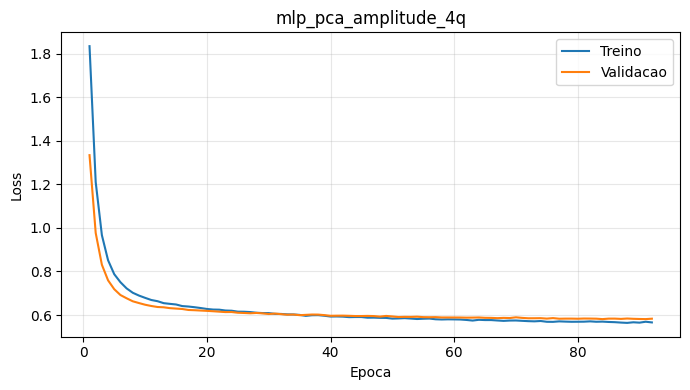

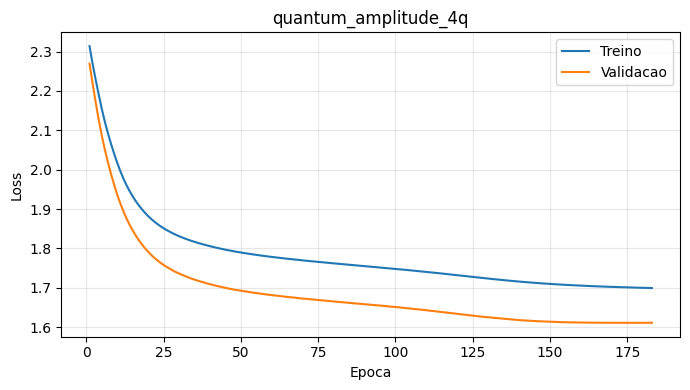

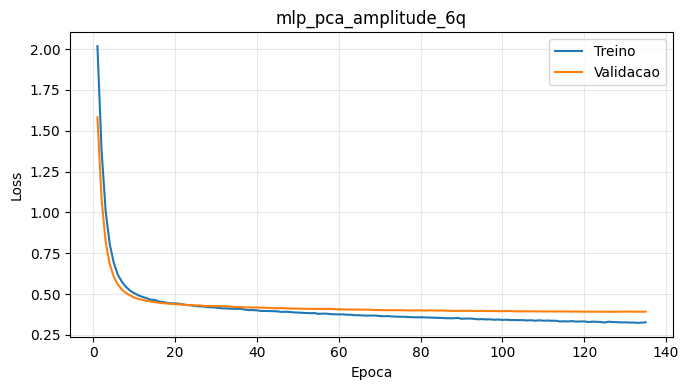

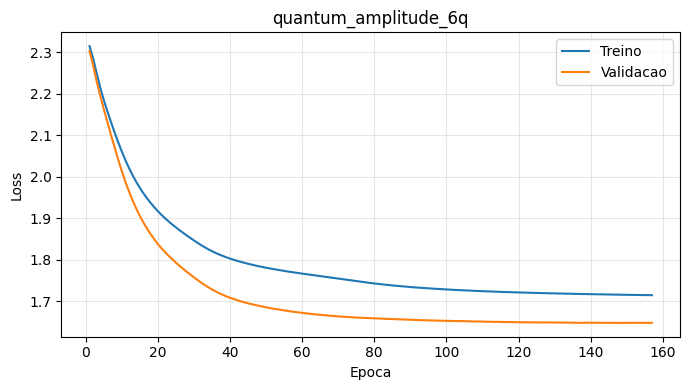

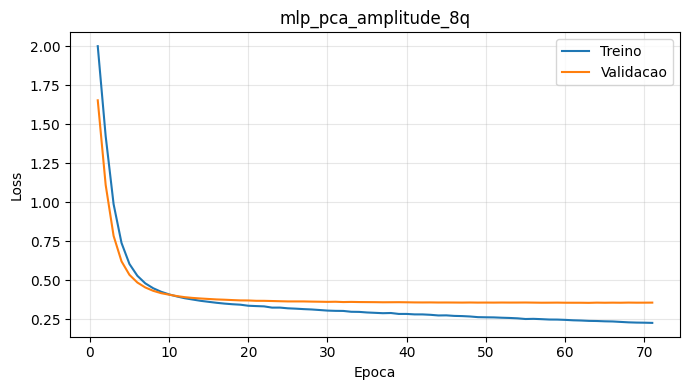

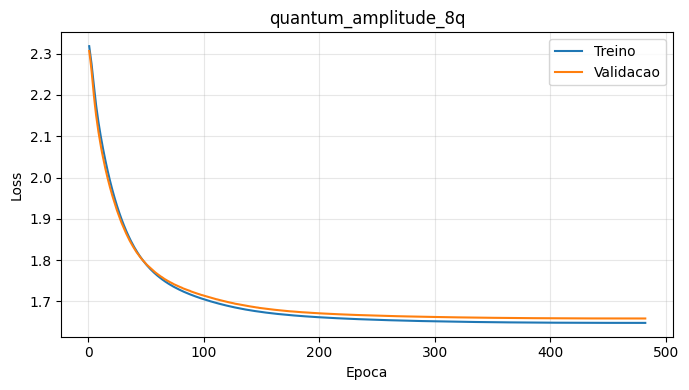

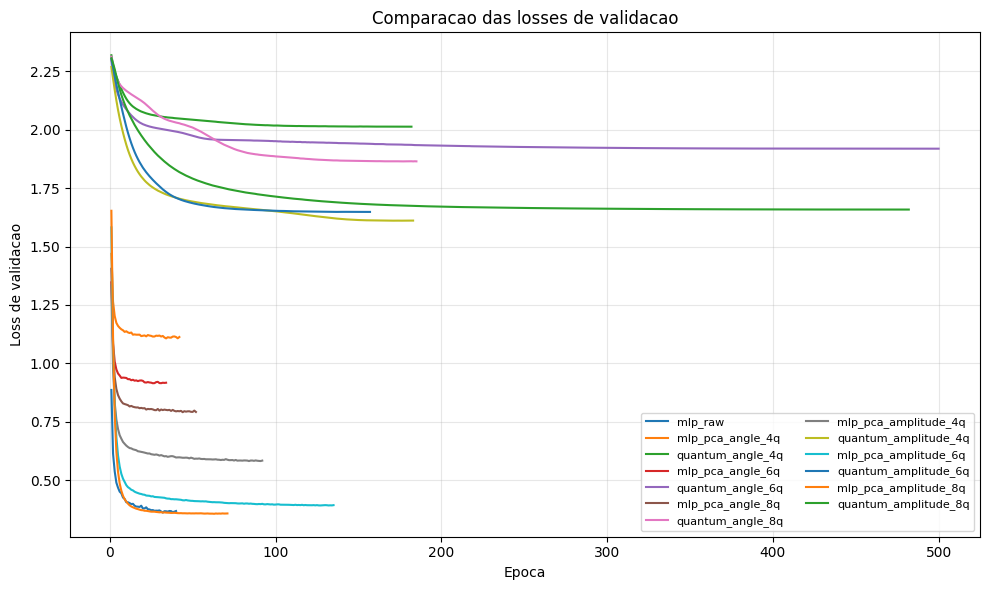

\begin{table}[ht]
\centering
\small
\begin{tabular}{lllllllll}
\toprule
Experimento & Modelo & Features & Reducao & Codificacao & Qubits & Test loss & Test acc. & Tempo (min) \\
\midrule
mlp\_raw & MLP & raw & Sem reducao & -- & -- & 0.3653 & 0.8711 & 0.31 \\
mlp\_pca\_angle\_4q & MLP & pca & PCA para 4 & angle & 4 & 1.1240 & 0.5540 & 0.28 \\
quantum\_angle\_4q & Hibrido & pca & PCA para 4 & angle & 4 & 2.0124 & 0.2584 & 115.82 \\
mlp\_pca\_angle\_6q & MLP & pca & PCA para 6 & angle & 6 & 0.9295 & 0.6428 & 0.21 \\
quantum\_angle\_6q & Hibrido & pca & PCA para 6 & angle & 6 & 1.9401 & 0.2781 & 462.62 \\
mlp\_pca\_angle\_8q & MLP & pca & PCA para 8 & angle & 8 & 0.8080 & 0.7043 & 0.29 \\
quantum\_angle\_8q & Hibrido & pca & PCA para 8 & angle & 8 & 1.8637 & 0.3280 & 245.46 \\
mlp\_pca\_amplitude\_4q & MLP & pca & PCA para 16 & amplitude & 4 & 0.6010 & 0.7855 & 0.51 \\
quantum\_amplitude\_4q & Hibrido & pca & PCA para 16 & amplitude & 4 & 1.6291 & 0.3976 & 99.09 \\
mlp\_pca\_amplitude\_6q

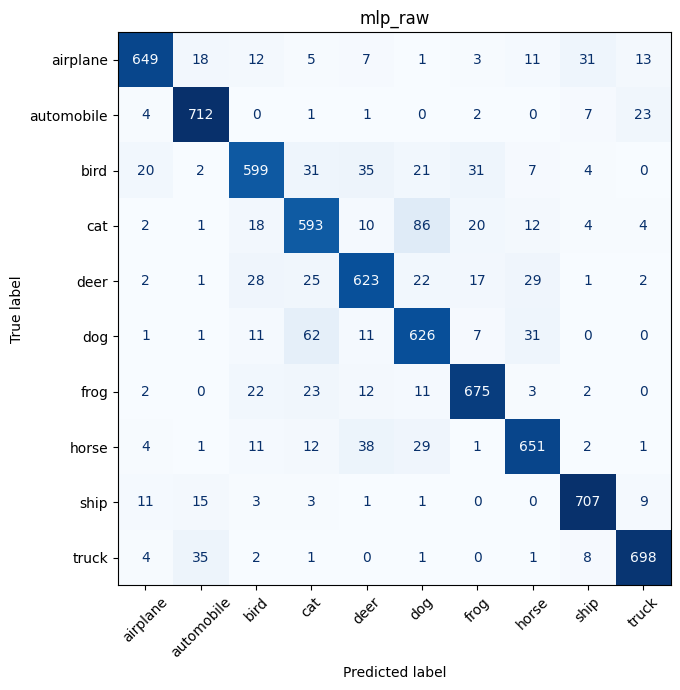

Matriz salva em: outputs/analysis_teste2/confusion_mlp_raw.png


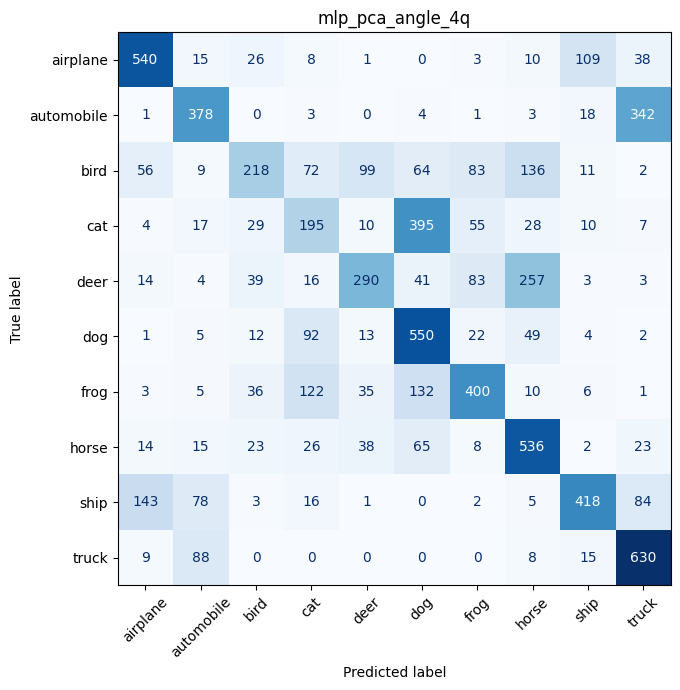

Matriz salva em: outputs/analysis_teste2/confusion_mlp_pca_angle_4q.png


/tmp/ipykernel_1193047/3045185010.py:191: UserWarning: Nao foi possivel gerar matriz de confusao para quantum_angle_4q: pennylane is required to use the quantum classifier.
  warnings.warn(f"Nao foi possivel gerar matriz de confusao para {name}: {error}")


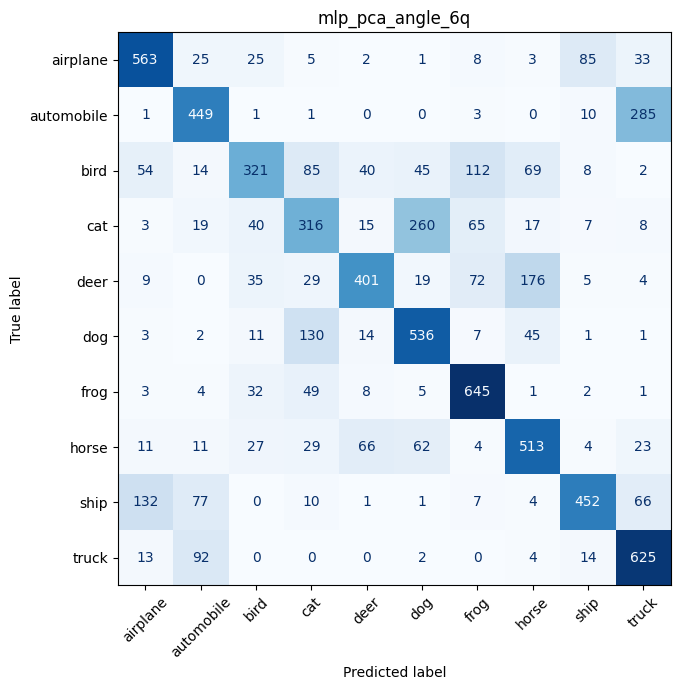

Matriz salva em: outputs/analysis_teste2/confusion_mlp_pca_angle_6q.png


/tmp/ipykernel_1193047/3045185010.py:191: UserWarning: Nao foi possivel gerar matriz de confusao para quantum_angle_6q: pennylane is required to use the quantum classifier.
  warnings.warn(f"Nao foi possivel gerar matriz de confusao para {name}: {error}")


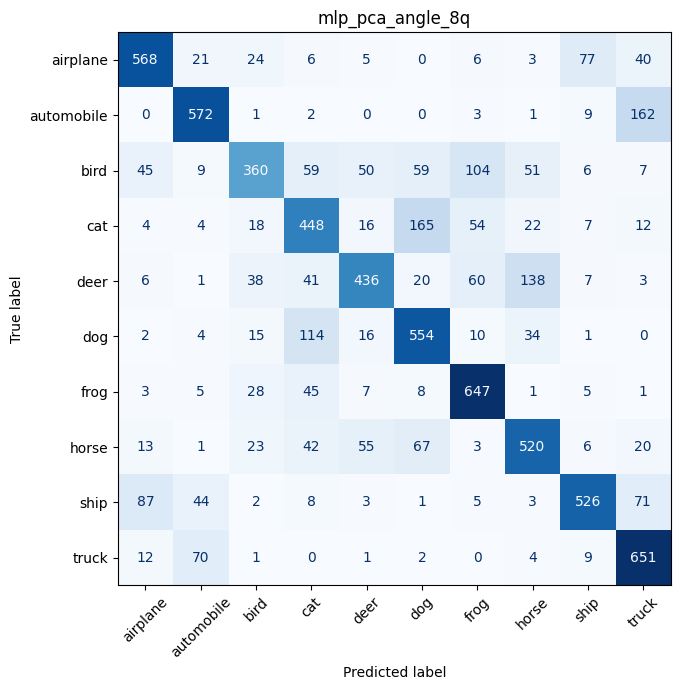

Matriz salva em: outputs/analysis_teste2/confusion_mlp_pca_angle_8q.png


/tmp/ipykernel_1193047/3045185010.py:191: UserWarning: Nao foi possivel gerar matriz de confusao para quantum_angle_8q: pennylane is required to use the quantum classifier.
  warnings.warn(f"Nao foi possivel gerar matriz de confusao para {name}: {error}")


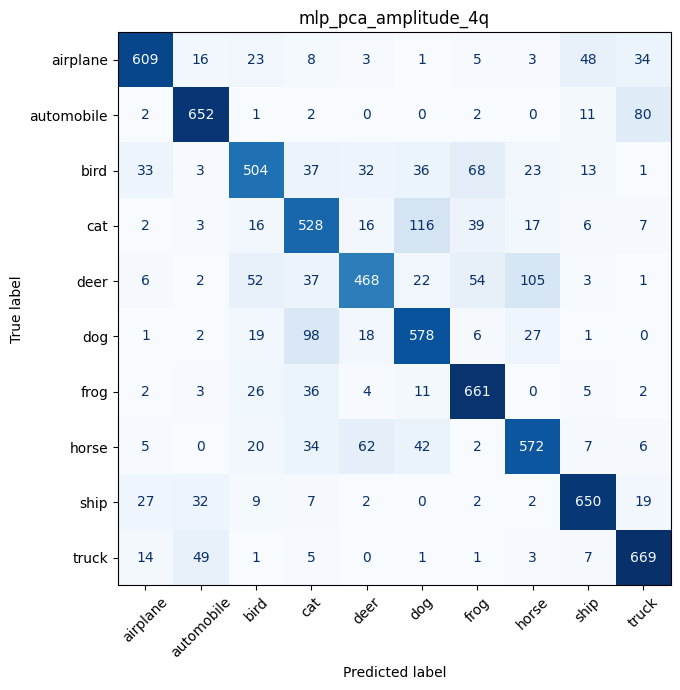

Matriz salva em: outputs/analysis_teste2/confusion_mlp_pca_amplitude_4q.png


/tmp/ipykernel_1193047/3045185010.py:191: UserWarning: Nao foi possivel gerar matriz de confusao para quantum_amplitude_4q: pennylane is required to use the quantum classifier.
  warnings.warn(f"Nao foi possivel gerar matriz de confusao para {name}: {error}")


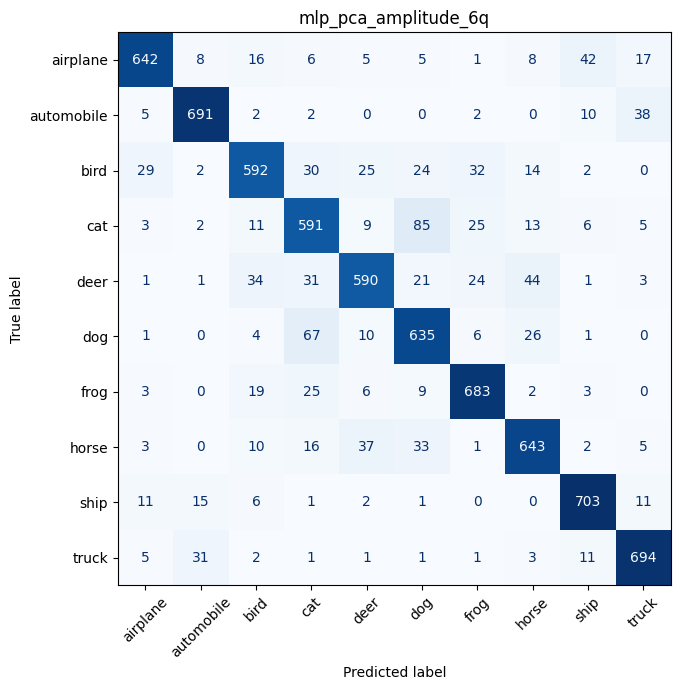

Matriz salva em: outputs/analysis_teste2/confusion_mlp_pca_amplitude_6q.png


/tmp/ipykernel_1193047/3045185010.py:191: UserWarning: Nao foi possivel gerar matriz de confusao para quantum_amplitude_6q: pennylane is required to use the quantum classifier.
  warnings.warn(f"Nao foi possivel gerar matriz de confusao para {name}: {error}")


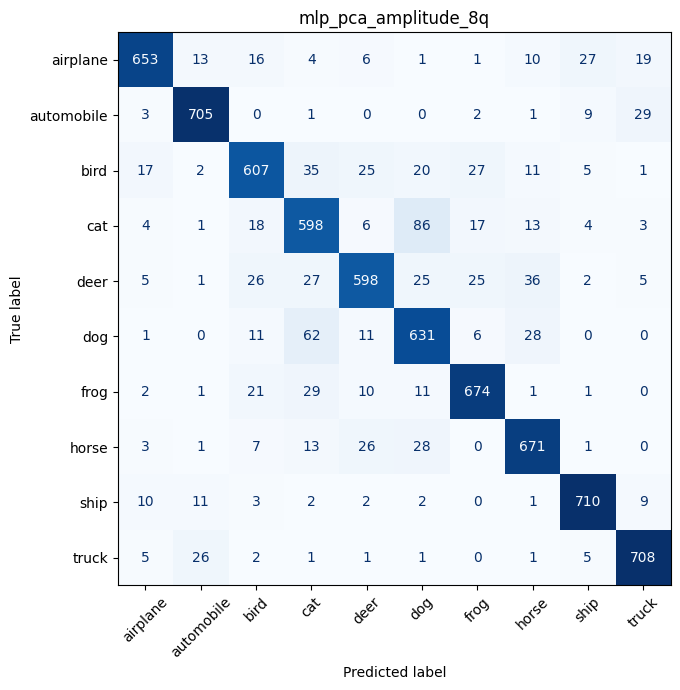

Matriz salva em: outputs/analysis_teste2/confusion_mlp_pca_amplitude_8q.png
Resumo das matrizes salvo em: outputs/analysis_teste2/confusion_summary.json


/tmp/ipykernel_1193047/3045185010.py:191: UserWarning: Nao foi possivel gerar matriz de confusao para quantum_amplitude_8q: pennylane is required to use the quantum classifier.
  warnings.warn(f"Nao foi possivel gerar matriz de confusao para {name}: {error}")


In [5]:
## Curvas de loss
def history_series(metrics, key):
    history = metrics.get("history", []) if metrics else []
    epochs = [item["epoch"] for item in history]
    train = [item["train"][key] for item in history]
    val = [item["val"][key] for item in history]
    return epochs, train, val

for record in finished:
    name = record["experiment"]["name"]
    epochs, train_loss, val_loss = history_series(record["metrics"], "loss")
    if not epochs:
        continue

    plt.figure(figsize=(7, 4))
    plt.plot(epochs, train_loss, label="Treino")
    plt.plot(epochs, val_loss, label="Validacao")
    plt.xlabel("Epoca")
    plt.ylabel("Loss")
    plt.title(name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(ANALYSIS_DIR / f"loss_{name}.png", dpi=200)
    plt.show()
plt.figure(figsize=(10, 6))

for record in finished:
    name = record["experiment"]["name"]
    epochs, _, val_loss = history_series(record["metrics"], "loss")
    if epochs:
        plt.plot(epochs, val_loss, label=name)

plt.xlabel("Epoca")
plt.ylabel("Loss de validacao")
plt.title("Comparacao das losses de validacao")
plt.grid(alpha=0.3)
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(ANALYSIS_DIR / "loss_validation_comparison.png", dpi=200)
plt.show()
## Tabela comparativa em LaTeX
def fmt_float(value, digits=4):
    if value in (None, ""):
        return "--"
    try:
        if math.isnan(float(value)):
            return "--"
        return f"{float(value):.{digits}f}"
    except (TypeError, ValueError):
        return str(value)

def latex_escape(value):
    value = str(value)
    replacements = {
        "\\": r"\textbackslash{}",
        "&": r"\&",
        "%": r"\%",
        "$": r"\$",
        "#": r"\#",
        "_": r"\_",
        "{": r"\{",
        "}": r"\}",
        "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}",
    }
    for old, new in replacements.items():
        value = value.replace(old, new)
    return value

table_rows = []
for record in finished:
    experiment = record["experiment"]
    metrics = record["metrics"]
    features = metrics.get("features", {})
    test = metrics.get("test", {})
    duration = metrics.get("duration", {})

    model_type = "Hibrido" if experiment["classifier"] == "quantum" else "MLP"
    feature_source = features.get("feature_source", experiment.get("feature_source", ""))
    feature_dim = features.get("feature_dim", "")
    reduction = f"PCA para {feature_dim}" if feature_source == "pca" else "Sem reducao"

    table_rows.append(
        [
            experiment["name"],
            model_type,
            feature_source,
            reduction,
            experiment.get("encoding") or "--",
            experiment.get("num_qubits") or "--",
            fmt_float(test.get("loss")),
            fmt_float(test.get("accuracy")),
            fmt_float(duration.get("minutes"), digits=2),
        ]
    )

headers = [
    "Experimento",
    "Modelo",
    "Features",
    "Reducao",
    "Codificacao",
    "Qubits",
    "Test loss",
    "Test acc.",
    "Tempo (min)",
]

latex_eol = " " + chr(92) * 2
latex_lines = [
    r"\begin{table}[ht]",
    r"\centering",
    r"\small",
    r"\begin{tabular}{lllllllll}",
    r"\toprule",
    " & ".join(latex_escape(header) for header in headers) + latex_eol,
    r"\midrule",
]

for row in table_rows:
    latex_lines.append(" & ".join(latex_escape(value) for value in row) + latex_eol)

latex_lines.extend(
    [
        r"\bottomrule",
        r"\end{tabular}",
        r"\caption{Comparacao dos classificadores avaliados.}",
        r"\label{tab:resultados-classificadores}",
        r"\end{table}",
    ]
)

latex_table = "\n".join(latex_lines)
table_path = ANALYSIS_DIR / "results_table.tex"
table_path.write_text(latex_table, encoding="utf-8")
print(latex_table)
print(f"Tabela salva em: {table_path}")
## Matrizes de confusao

def feature_source_and_dim(experiment):
    if experiment["classifier"] == "quantum":
        return "pca", experiment["pca_dim"]
    if experiment["feature_source"] == "pca":
        return "pca", experiment["pca_dim"]
    return "raw", None

def predict_labels(model, loader, device):
    y_true = []
    y_pred = []
    model.eval()
    with torch.no_grad():
        for features, labels in loader:
            features = features.to(device)
            outputs = model(features)
            y_true.extend(labels.cpu().numpy().tolist())
            y_pred.extend(outputs.argmax(dim=1).cpu().numpy().tolist())
    return np.array(y_true), np.array(y_pred)

confusion_results = []

for record in records:
    experiment = record["experiment"]
    name = experiment["name"]
    checkpoint_path = record["checkpoint_path"]

    if record["metrics"] is None or not checkpoint_path.exists():
        print(f"Pulando {name}: metrics.json ou checkpoint ausente.")
        continue

    source, dim = feature_source_and_dim(experiment)
    batch_size = config.get("features", {}).get("batch_size", config["dataset"].get("batch_size", 64))
    if experiment["classifier"] == "quantum":
        batch_size = config.get("features", {}).get("quantum_batch_size", batch_size)

    try:
        loaders = load_feature_loaders(record["config"], source, dim, batch_size=batch_size)
    except FileNotFoundError as error:
        print(f"Pulando {name}: cache de features ausente ({error}).")
        continue

    input_dim = loaders["test_loader"].dataset.tensors[0].size(1)
    device = torch.device("cpu") if experiment["classifier"] == "quantum" else torch.device("cuda" if torch.cuda.is_available() else "cpu")

    try:
        model = build_feature_classifier(input_dim, record["config"]["model"]).to(device)
        state_dict = torch.load(checkpoint_path, map_location=device)
        model.load_state_dict(state_dict)
        y_true, y_pred = predict_labels(model, loaders["test_loader"], device)
    except Exception as error:
        warnings.warn(f"Nao foi possivel gerar matriz de confusao para {name}: {error}")
        continue

    matrix = confusion_matrix(y_true, y_pred, labels=list(range(config["model"]["num_classes"])))
    fig, ax = plt.subplots(figsize=(7, 7))
    labels = CLASS_NAMES if len(CLASS_NAMES) == config["model"]["num_classes"] else list(range(config["model"]["num_classes"]))
    display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=labels)
    display.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
    ax.set_title(name)
    plt.tight_layout()
    output_path = ANALYSIS_DIR / f"confusion_{name}.png"
    plt.savefig(output_path, dpi=200)
    plt.show()

    confusion_results.append({"experiment": name, "path": str(output_path), "accuracy": float((y_true == y_pred).mean())})
    print(f"Matriz salva em: {output_path}")

confusion_summary_path = ANALYSIS_DIR / "confusion_summary.json"
confusion_summary_path.write_text(json.dumps(confusion_results, indent=2), encoding="utf-8")
print(f"Resumo das matrizes salvo em: {confusion_summary_path}")